# Más allá: las reconciliaciones contra motores de referencia que existen hoy

**Pregunta:** ¿Da el motor los números que imprimieron los artículos que implementa, y donde no, por qué: cuántos números impresos puede recalcular un lector desde las entradas versionadas, cuántos coinciden hasta el dígito impreso, y qué explica cada brecha?

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los notebooks 03, 05 y 06 de este tema (el problema de inmersión, la calibración y las cotas de bajo incumplimiento)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- recalcular con el motor las tablas impresas de tres artículos de los casos de calificaciones y calibración (Pluto y Tasche 2005, Tasche 2013, Schuermann y Hanson 2004) y contar cuántos números impresos coinciden hasta el dígito impreso y por cuánto fallan los demás;
- leer las brechas que registran los artefactos versionados para los otros dos artículos (Israel, Rosenthal y Wei; Engelmann) y decir qué explica cada una;
- verificar los valores p del motor en una grilla contra una cuadratura de la densidad Beta y una suma exacta de los términos binomiales, y decir por qué una comparación con las llamadas de SciPy que hace el propio motor no probaría nada;
- decir qué reconciliaciones de la afirmación pertenecen a otro notebook o no se vuelven a correr aquí;
- enunciar la afirmación BS-2 del producto, la evidencia que la respalda y sus límites.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import low_default as ldp
from riskvalidation.engines import pd_curve as pc
from riskvalidation.transitions import intervals
from riskvalidation.validation import calibration as cal

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro archivos versionados, todos producidos por el flujo de procesamiento del producto desde artículos que son fuentes de solo derivados (los artefactos llevan los números impresos, tasas y perfiles, nunca las tablas de conteos de los propios artículos):

- `data/derived/C04/published.json`: tres artículos junto a sus impresiones. Israel, Rosenthal y Wei (2001): nueve distancias L1, registradas con su recálculo. Schuermann y Hanson (2004), Tabla 5: el conteo de deudores y de incumplimientos y los intervalos de Wald y de Agresti-Coull impresos para BB en 2002. Engelmann (2024): la cartera TTC y cuatro carteras iniciales, registradas con su recálculo.
- `data/derived/C05/sp-2010.json` y `sp-2011.json`: Tasche (2013), Tablas 5 a 9 (`outputs.golden`): la curva suavizada impresa, el perfil implícito, las curvas de pronóstico de cuatro enfoques, las PD del caso 3 y las razones de verosimilitud, con las tasas y perfiles que el motor necesita para reconstruirlas.
- `data/derived/C05/ldp-published.json`: Pluto y Tasche (2005), Tablas 1 a 14, 204 celdas impresas (`outputs.golden.cells`), con la cartera del ejemplo del artículo.

Las pruebas de reconciliación propias del repositorio (`tests/test_c04_parity.py`, `tests/test_c04_published.py`, `tests/test_c05.py`) corren en la suite de pruebas del producto, no aquí. Este notebook recalcula con el motor lo que permiten las entradas versionadas, y lee el resto tal como está registrado.

In [2]:
# Load the committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
published = json.loads((DERIVED / "C04" / "published.json").read_text(encoding="utf-8"))["outputs"]
ldp_doc = json.loads((DERIVED / "C05" / "ldp-published.json").read_text(encoding="utf-8"))["outputs"]
tasche = {}
for year in (2010, 2011):
    document = json.loads((DERIVED / "C05" / f"sp-{year}.json").read_text(encoding="utf-8"))
    tasche[year] = document["outputs"]

## Método

### Paso 1: Pluto y Tasche, Tablas 1 a 12

Una reconciliación recalcula un número impreso con el motor y pone los dos lado a lado. Un valor recalculado coincide con su impresión cuando queda a menos de media unidad del último dígito impreso: 2,7245 y 2,7255 coinciden ambos con 2,725, porque una impresión no dice cómo se redondeó. El primer artículo es Pluto y Tasche (2005), la estimación más prudente de una PD para una cartera con pocos incumplimientos o ninguno: tres grados de 100, 400 y 300 deudores, con cero incumplimientos o con 0, 2 y 1. Las Tablas 1 a 6 dan la cota superior independiente en seis niveles de confianza, las Tablas 7 y 8 la cota con una correlación de activos de 12%, y las Tablas 9 a 12 escalan las cotas de los tres grados a un objetivo de cartera (un multiplicador $k$ y las PD escaladas). La celda siguiente recalcula las 168 celdas de las Tablas 1 a 12 con `most_prudent_pd` y `most_prudent_pd_scaled` del motor.

In [3]:
# Recompute Tables 1 to 12 of Pluto and Tasche with the engine's most prudent estimate
obligors, few, zero = tuple(ldp_doc["obligors"]), tuple(ldp_doc["defaults"]), (0, 0, 0)
gammas, rho = ldp_doc["gammas"], ldp_doc["rho"]
rows = ("pa", "pb", "pc")
scaled_tables = (
    (9, 0.0, "central_tendency"),
    (10, rho, "central_tendency"),
    (11, 0.0, "upper_bound"),
    (12, rho, "upper_bound"),
)
ours_pt = {}
for g in gammas:
    independent_zero = ldp.most_prudent_pd(obligors, zero, g)["pd"]
    independent_few = ldp.most_prudent_pd(obligors, few, g)["pd"]
    correlated_zero = ldp.most_prudent_pd(obligors, zero, g, rho)["pd"]
    correlated_few = ldp.most_prudent_pd(obligors, few, g, rho)["pd"]
    for j, row in enumerate(rows):
        ours_pt[(1 + j, row, g)] = 100 * independent_zero[j]
        ours_pt[(4 + j, row, g)] = 100 * independent_few[j]
        ours_pt[(7, row, g)] = 100 * correlated_zero[j]
        ours_pt[(8, row, g)] = 100 * correlated_few[j]
    for table, r, target in scaled_tables:
        scaled = ldp.most_prudent_pd_scaled(obligors, few, g, r, target=target)
        ours_pt[(table, "k", g)] = scaled["k"]
        for j, row in enumerate(rows):
            ours_pt[(table, row + ",scaled", g)] = 100 * scaled["pd"][j]

first_twelve = [c for c in ldp_doc["golden"]["cells"] if c["table"] <= 12]
printed_pt = {(c["table"], c["row"], c["gamma"]): c["printed"] for c in first_twelve}
print("celdas recalculadas:", len(ours_pt), "| celdas impresas en las Tablas 1 a 12:", len(printed_pt))
print("Tabla 4, grado A, por nivel, recalculado:", [round(ours_pt[(4, "pa", g)], 4) for g in gammas])
print("Tabla 4, grado A, por nivel, impreso:", [printed_pt[(4, "pa", g)] for g in gammas])

celdas recalculadas: 168 | celdas impresas en las Tablas 1 a 12: 168
Tabla 4, grado A, por nivel, recalculado: [0.4588, 0.6378, 0.8332, 0.9663, 1.2501, 1.6225]
Tabla 4, grado A, por nivel, impreso: [0.46, 0.65, 0.83, 0.97, 1.25, 1.62]


La figura dibuja cada porcentaje recalculado frente a su valor impreso en ejes logarítmicos, coloreado según la familia de tablas, con la diagonal donde ambos son iguales.

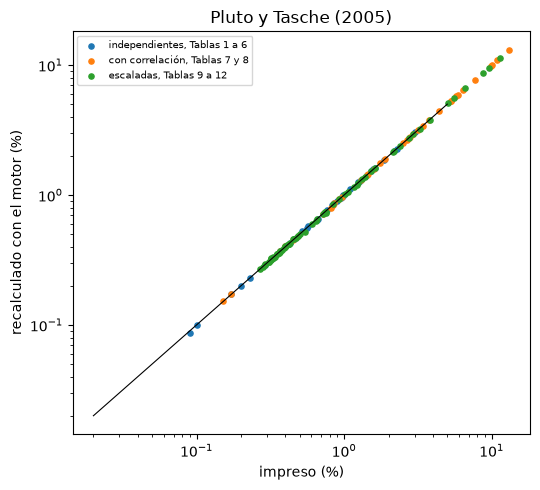

In [4]:
# Draw the recomputed against the printed values of Tables 1 to 12 (the multiplier k aside)
families = (("independientes, Tablas 1 a 6", range(1, 7)),
            ("con correlación, Tablas 7 y 8", (7, 8)),
            ("escaladas, Tablas 9 a 12", range(9, 13)))
fig, ax = plt.subplots(figsize=(5.5, 5))
for label, tables in families:
    keys = [k for k in printed_pt if k[0] in tables and k[1] != "k"]
    ax.scatter([printed_pt[k] for k in keys], [ours_pt[k] for k in keys], s=14, label=label)
ax.plot([0.02, 5], [0.02, 5], color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("impreso (%)")
ax.set_ylabel("recalculado con el motor (%)")
ax.set_title("Pluto y Tasche (2005)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Los puntos quedan sobre la diagonal a lo largo de dos órdenes de magnitud, desde cotas bajo 0,1% hasta cotas sobre 10%, y para las tres familias de tablas por igual. Una lectura a esta escala no puede mostrar las celdas que fallan por una o dos unidades del último dígito impreso, que el recuento de abajo cuenta una por una. Muestra que ninguna familia de tablas difiere por un método o una convención distintos: el motor no queda sistemáticamente sobre o bajo el artículo, y una brecha, donde la hay, es cuestión del último dígito o de dos.

### Paso 2: Tasche (2013), Tablas 5 a 9

El segundo artículo es la calibración de una curva de PD de los notebooks 05 y 09. Los archivos versionados contienen las tablas impresas y las tasas y perfiles que necesita el motor, de modo que la curva de 2009, el perfil de incumplimiento implícito y las razones de verosimilitud de las Tablas 5, 6 y 9 pueden reconstruirse desde ellos. La celda siguiente ajusta la curva por ajuste cuasi de momentos y lee de ella las tres tablas de 2009.

In [5]:
# Rebuild the 2009 curve of Tasche (2013) by quasi moment matching and the 2009 tables the paper prints
base = tasche[2010]
survival0 = np.array(base["profile0"]) * (1 - np.array(base["default_rate0"]))
survival0 = survival0 / survival0.sum()
start = pc.qmm(base["profile0"], base["pd0"], base["ar0"], survival_profile=list(survival0))
curve0 = np.array(start["pd_curve"])
ours_t = {"table5": 100 * curve0}
ours_t["table6"] = 100 * np.array(pc.implied_default_profile(curve0, base["profile0"]))
ours_t["table9"] = np.array(pc.likelihood_ratio(curve0, start["pd"]))

golden = base["golden"]
printed_t = {"table5": np.array([c["printed"] for c in golden["table5"]])}
printed_t["table6"] = np.array([c["printed"] for c in golden["table6"]])
printed_t["table9"] = np.array([c["printed"] for c in golden["table9_2009"]])
print(f"QMM: alpha {start['alpha']:.4f}, beta {start['beta']:.4f}")
print("Table 5, peor grado, impreso y recalculado (%):", printed_t["table5"][-1], round(ours_t["table5"][-1], 4))

QMM: alpha 5.2048, beta 2.1613
Table 5, peor grado, impreso y recalculado (%): 48.355 48.3537


La celda siguiente lleva la curva a 2010 y 2011 con los cuatro enfoques del caso 1 cuyas curvas imprime la Tabla 7, y con los cuatro enfoques del caso 3 cuyas PD de pronóstico imprime la Tabla 8, tal como en el notebook 09.

In [6]:
# Carry the curve to 2010 and 2011: the four curves of Table 7 and the four forecasts of Table 8
ours_t["table7"], ours_t["table8"], printed_t["table7"], printed_t["table8"] = {}, {}, {}, {}
for year, o in tasche.items():
    p1, pd1, pd0 = o["profile1"], o["pd1"], start["pd"]
    dp0 = pc.implied_default_profile(curve0, o["profile0"])
    sv0 = pc.implied_survival_profile(curve0, o["profile0"])
    case1 = {
        "A1-idp": pc.invariant_default_profile(o["default_profile0"], p1, pd1),
        "A2-iar": pc.invariant_accuracy_ratio(p1, pd1, o["ar0"]),
        "A3-spd": pc.scaled_pds(curve0, p1, pd1),
        "A4-slr": pc.scaled_likelihood_ratio(curve0, pd0, p1, pd1),
    }
    ours_t["table7"][year] = {a: 100 * np.array(r["pd_curve"]) for a, r in case1.items()}
    printed_t["table7"][year] = {a: np.array([c["printed"] for c in o["golden"]["table7"][a]]) for a in case1}
    least_squares = pc.invariant_conditional_profiles(dp0, sv0, p1, fit="least_squares")
    least_chi2 = pc.invariant_conditional_profiles(dp0, sv0, p1, fit="least_chi2")
    unchanged = pc.invariant_pd_curve(curve0, p1)["pd_curve"]
    ratio_known = pc.invariant_likelihood_ratio(curve0, pd0, profile_1=p1)
    case3 = [pc.unconditional_pd(unchanged, p1), least_squares["pd"], least_chi2["pd"], ratio_known["pd"]]
    ours_t["table8"][year] = 100 * np.array(case3)
    printed_t["table8"][year] = np.array([c["printed_pct"] for c in o["golden"]["table8"]])
print("Table 8, 2010, impreso:", printed_t["table8"][2010], "| recalculado:", np.round(ours_t["table8"][2010], 3))

Table 8, 2010, impreso: [4.32 4.8  5.35 5.38] | recalculado: [4.318 4.799 5.347 5.377]


La figura dibuja a la izquierda la curva de 2009 frente a su Tabla 5 impresa, y a la derecha las cuatro curvas del caso 1 de 2010 frente a su Tabla 7 impresa.

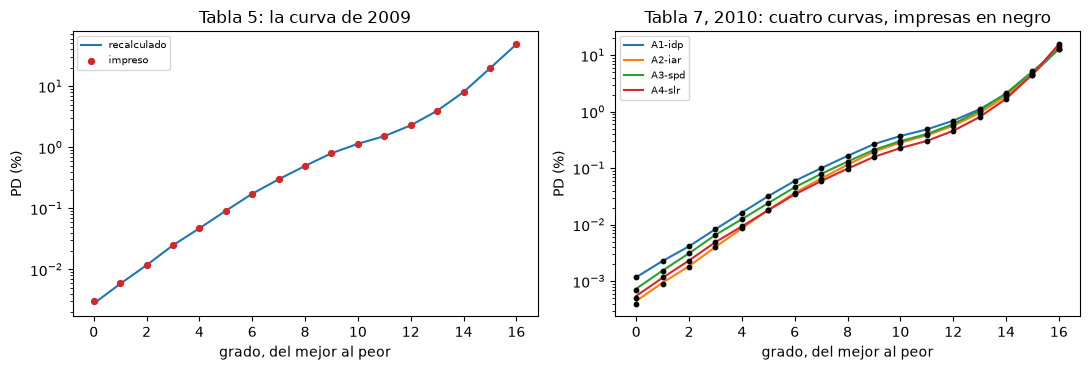

In [7]:
# Draw the 2009 curve and the 2010 curves, recomputed lines against printed markers
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(printed_t["table5"]))
left.plot(x, ours_t["table5"], color="tab:blue", label="recalculado")
left.scatter(x, printed_t["table5"], color="tab:red", s=18, zorder=3, label="impreso")
left.set_yscale("log")
left.set_title("Tabla 5: la curva de 2009")
for a, curve in ours_t["table7"][2010].items():
    right.plot(x, curve, label=a)
    right.scatter(x, printed_t["table7"][2010][a], s=10, color="black", zorder=3)
right.set_yscale("log")
right.set_title("Tabla 7, 2010: cuatro curvas, impresas en negro")
for ax in (left, right):
    ax.set_xlabel("grado, del mejor al peor")
    ax.set_ylabel("PD (%)")
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

Las curvas recalculadas pasan por los puntos impresos a lo largo de cuatro órdenes de magnitud, en la curva de 2009 y en cada una de las cuatro curvas de pronóstico de 2010, de modo que el ajuste cuasi de momentos del motor y sus cuatro enfoques dan los números del artículo. A esta escala no se ve un error de una unidad del cuarto decimal en un porcentaje, y el recuento de abajo los cuenta. La figura también esconde el piso de PD y los grados con las PD más pequeñas, donde la impresión tiene muy pocos dígitos significativos para comparar: el panel derecho deja de ser informativo bajo cerca de 0,001%.

### Paso 3: Schuermann y Hanson (2004), Tabla 5

El tercer artículo imprime los intervalos de Wald y de Agresti-Coull al 95% del grado BB en 2002, con 531 deudores, con tres valores de la correlación de incumplimiento (0, 0,01 y 0,02), cada uno como cota inferior, cota superior y largo. La tabla no imprime el número de incumplimientos; el artefacto registra el único conteo, 15, cuya cota inferior de Wald independiente se imprime como la de la tabla. La celda siguiente corre `pd_wald` y `pd_agresti_coull` del motor con cada correlación, donde la correlación entra por el tamaño efectivo de muestra de la ecuación (3.4) del artículo.

In [8]:
# Recompute the six intervals of Table 5 of Schuermann and Hanson with the engine
sr = published["sr190"]
ours_sr, printed_sr = [], []
for row in sr["rows"]:
    settings = {"level": 0.95, "rho": row["rho"]}
    if row["interval"] == "wald":
        result = intervals.pd_wald(sr["defaults"], sr["n"], **settings)
    else:
        result = intervals.pd_agresti_coull(sr["defaults"], sr["n"], **settings)
    ours_sr += [float(result[key]) for key in ("lower", "upper", "length")]
    printed_sr += row["printed"]
    print(f"{row['interval']:14s} rho {row['rho']:.2f}: impreso {row['printed']}")
    print(f"{'':14s} {'':8s}  recalculado {np.round(ours_sr[-3:], 6)}")

wald           rho 0.00: impreso [0.014156, 0.042341, 0.028184]
                         recalculado [0.014156 0.042341 0.028184]
wald           rho 0.01: impreso [0.0, 0.06362, 0.06362]
                         recalculado [0.      0.06362 0.06362]
wald           rho 0.02: impreso [0.0, 0.076245, 0.076245]
                         recalculado [0.       0.076245 0.076245]
agresti_coull  rho 0.00: impreso [0.016803, 0.046471, 0.029668]
                         recalculado [0.016803 0.046471 0.029668]
agresti_coull  rho 0.01: impreso [0.003825, 0.0938, 0.089975]
                         recalculado [0.003825 0.0938   0.089975]
agresti_coull  rho 0.02: impreso [0.0, 0.133256, 0.133256]
                         recalculado [0.       0.133256 0.133256]


Cada triple impreso es el recalculado a los seis decimales impresos. Las únicas entradas son los 531 deudores y los 15 incumplimientos, de modo que los intervalos son una prueba directa de las fórmulas de la sección 3 del artículo, incluida la corrección por efecto de diseño con correlación positiva, que ensancha el intervalo a medida que crece la correlación. Son las cotas del grado BB, una sola tabla del artículo; lo que la coincidencia no muestra es que el motor reproduzca las demás estimaciones del artículo, como las que usan datos de duración.

### Paso 4: los valores p de las pruebas de Jeffreys y binomial, contra dos recálculos independientes

Muchas pruebas del motor son una probabilidad de cola de una distribución estándar: la prueba de Jeffreys es una función de distribución Beta y la prueba binomial una cola binomial. El motor las calcula con `scipy.stats.beta.cdf(pd, d + 1/2, n - d + 1/2)` y `scipy.stats.binom.sf(d - 1, n, pd)`. Una comparación con esas mismas dos llamadas daría una diferencia de 0 por construcción: mostraría que la parametrización y la convención de la cola son las escritas, y pasaría aun si SciPy estuviera mal. La reconciliación de aquí usa dos rutas que no llaman a ninguna de las dos funciones:

- el valor p de Jeffreys como la integral de la densidad Beta de 0 a la PD aplicada. La sustitución $x = p\,u^2$ convierte la densidad, singular en 0, en el integrando suave $2\,p^{a} u^{2d} (1 - p u^2)^{b-1}$, con $a = d + \tfrac12$ y $b = n - d + \tfrac12$, que una regla de Gauss-Legendre de 400 puntos integra hasta la precisión de máquina, dividida por la función Beta escrita con `math.lgamma`;
- el valor p binomial como uno menos la suma exacta de los primeros $d$ términos binomiales, en aritmética racional (`fractions.Fraction` de la PD en coma flotante y `math.comb`), redondeado una sola vez al final.

La celda siguiente llama a las dos pruebas del motor en una grilla de 36 casos (deudores, incumplimientos, PD aplicada) y guarda las diferencias con cada ruta.

In [9]:
# Compare the engine's Jeffreys and binomial p-values with two routes that call neither of its SciPy functions
grid = [(n, d, p) for n in (50, 500, 5000) for d in (0, 1, 3, 10) for p in (0.001, 0.01, 0.05)]
nodes, weights = np.polynomial.legendre.leggauss(400)
u, w = (nodes + 1) / 2, weights / 2
jeffreys_gap, binomial_gap = [], []
for n, d, p in grid:
    a, b = d + 0.5, n - d + 0.5
    integral = 2 * p**a * np.sum(w * u ** (2 * d) * (1 - p * u**2) ** (b - 1))
    jeffreys_route = integral / math.exp(math.lgamma(a) + math.lgamma(b) - math.lgamma(a + b))
    q = Fraction(p)
    binomial_route = float(1 - sum(math.comb(n, k) * q**k * (1 - q) ** (n - k) for k in range(d)))
    jeffreys_gap.append(abs(cal.pd_jeffreys(n=n, d=d, pd=p).p_value - jeffreys_route))
    binomial_gap.append(abs(cal.pd_binomial(n=n, d=d, pd=p).p_value - binomial_route))
print("casos:", len(grid))
print("Jeffreys: mayor diferencia con la cuadratura de la densidad Beta:", f"{max(jeffreys_gap):.1e}")
print("binomial: mayor diferencia con la suma exacta de los términos binomiales:", f"{max(binomial_gap):.1e}")

casos: 36
Jeffreys: mayor diferencia con la cuadratura de la densidad Beta: 5.7e-12
binomial: mayor diferencia con la suma exacta de los términos binomiales: 5.6e-16


La figura dibuja las 72 diferencias en un eje logarítmico frente a una tolerancia de 1e-9, las de Jeffreys frente a la cuadratura y las binomiales frente a la suma exacta.

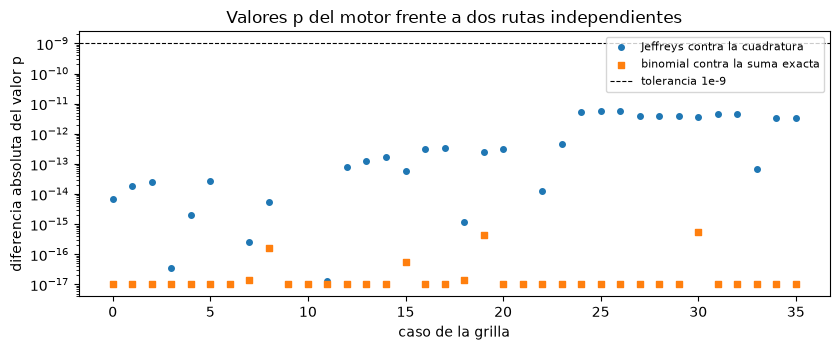

In [10]:
# Draw the differences of the engine's p-values to the two independent routes
fig, ax = plt.subplots(figsize=(8.5, 3.6))
floor = 1e-17
label_j = "Jeffreys contra la cuadratura"
label_b = "binomial contra la suma exacta"
ax.scatter(range(len(grid)), np.maximum(jeffreys_gap, floor), s=16, label=label_j)
ax.scatter(range(len(grid)), np.maximum(binomial_gap, floor), s=16, marker="s", label=label_b)
ax.axhline(1e-9, color="black", linestyle="--", linewidth=0.8, label="tolerancia 1e-9")
ax.set_yscale("log")
ax.set_xlabel("caso de la grilla")
ax.set_ylabel("diferencia absoluta del valor p")
ax.set_title("Valores p del motor frente a dos rutas independientes")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Toda diferencia queda muy bajo la tolerancia: los valores p de Jeffreys coinciden con la cuadratura de la densidad Beta hasta cerca de 1e-11 y los binomiales con la suma exacta hasta el límite de la aritmética de coma flotante, 1e-16 y menos. Los puntos dibujados al fondo del eje son ceros exactos, recortados para la escala logarítmica. La coincidencia se mantiene entre tamaños de muestra de 50 a 5.000, de cero a diez incumplimientos y PD de 0,1% a 5%, donde los cálculos Beta y binomial son más delicados. La figura no dice nada sobre otras distribuciones de SciPy ni sobre las pruebas del motor que no son una cola estándar.

### Paso 5: el recuento, y las brechas con lo que las explica

El recuento cuenta, para cada tabla recalculada arriba, cuántos números impresos coinciden hasta el dígito impreso (a media unidad del último dígito impreso) y la mayor brecha en la unidad de la impresión. Las tres últimas fuentes se leen como las registran los artefactos, porque sus entradas no están versionadas: las matrices de agencia de Israel, Rosenthal y Wei y la matriz de Engelmann son tablas de artículos que la clase de licencia mantiene fuera del repositorio, y las Tablas 13 y 14 de Pluto y Tasche son corridas de Monte Carlo de 100.000 muestras que este notebook no repite. La celda es la única verificación de reproducción del notebook.

In [11]:
# Tally the printed numbers by source: how many, how many agree to the printed digit, the largest gap
keys = sorted(printed_pt, key=str)
compared = [
    ("Pluto y Tasche (2005), Tablas 1 a 12", [ours_pt[k] for k in keys],
     [printed_pt[k] for k in keys], 2, "pp"),
    ("Tasche (2013), Tabla 5", ours_t["table5"], printed_t["table5"], 3, "pp"),
    ("Tasche (2013), Tabla 6", ours_t["table6"], printed_t["table6"], 4, "pp"),
    ("Tasche (2013), Tabla 9, 2009", ours_t["table9"], printed_t["table9"], 2, "razón"),
    ("Schuermann y Hanson (2004), Tabla 5", ours_sr, printed_sr, 6, "prob."),
]
for year in tasche:
    flat_ours = np.concatenate([ours_t["table7"][year][a] for a in ours_t["table7"][year]])
    flat_printed = np.concatenate([printed_t["table7"][year][a] for a in printed_t["table7"][year]])
    compared.append((f"Tasche (2013), Tabla 7, {year}", flat_ours, flat_printed, 4, "pp"))
    compared.append((f"Tasche (2013), Tabla 8, {year}", ours_t["table8"][year], printed_t["table8"][year], 2, "pp"))
tally, gaps = [], {}
for name, ours, printed, decimals, unit in compared:
    gap = np.array(ours) - np.array(printed)
    gaps[name] = gap
    agree = int(np.sum(np.abs(gap) <= 0.5 * 10.0**-decimals + 1e-9))
    tally.append((name, gap.size, agree, float(np.abs(gap).max()), unit, "recomputed"))
for row in tally:
    print(f"{row[0]:42s}{row[1]:6d}{row[2]:6d}{row[3]:10.4f}  {row[4]}")

Pluto y Tasche (2005), Tablas 1 a 12         168   125    0.0951  pp
Tasche (2013), Tabla 5                        17    15    0.0013  pp
Tasche (2013), Tabla 6                        17     8    0.0013  pp
Tasche (2013), Tabla 9, 2009                  17    10    0.3579  razón
Schuermann y Hanson (2004), Tabla 5           18    18    0.0000  prob.
Tasche (2013), Tabla 7, 2010                  68    54    0.0005  pp
Tasche (2013), Tabla 8, 2010                   4     4    0.0035  pp
Tasche (2013), Tabla 7, 2011                  68    52    0.0004  pp
Tasche (2013), Tabla 8, 2011                   4     3    0.0057  pp


Se cuentan las fuentes recalculadas. La celda siguiente agrega las tres fuentes leídas tal como están registradas, desde los artefactos versionados, con la misma regla de coincidencia, e imprime los totales.

In [12]:
# Add the sources read as recorded: Israel et al., Engelmann and Tables 13 and 14 of Pluto and Tasche
irw = published["irw"]["rows"]
irw_gap = max(abs(r["printed"] - r["recomputed"]) for r in irw)
tally.append(("Israel et al. (2001), distancias L1", len(irw), sum(r["agrees"] for r in irw), irw_gap, "L1", "read"))
eng = published["engelmann"]
checks = list(zip(eng["w_ttc"]["printed"], eng["w_ttc"]["recomputed"], eng["w_ttc"]["decimals"]))
checks.append((eng["ttc_pd"]["printed"], eng["ttc_pd"]["recomputed"], eng["ttc_pd"]["decimals"]))
starts = [q["pd0"] for q in eng["portfolios"] if q["pd0"]["check"] == "printed digits"]
checks += [(s0["printed"], s0["recomputed"], s0["decimals"]) for s0 in starts]
agree = sum(abs(r - p) <= 0.5 * 10.0**-d + 1e-9 for p, r, d in checks)
eng_gap = max(abs(r - p) for p, r, _ in checks)
tally.append(("Engelmann (2024), cartera TTC y PD", len(checks), int(agree), eng_gap, "prob.", "read"))
late = [c["gap"] for c in ldp_doc["golden"]["cells"] if c["table"] >= 13]
late_name = "Pluto y Tasche (2005), Tablas 13 y 14"
tally.append((late_name, len(late), sum(g == 0 for g in late), max(abs(g) for g in late), "pp", "read"))
total, agree_total = sum(r[1] for r in tally), sum(r[2] for r in tally)
recomputed_n = sum(r[1] for r in tally if r[5] == "recomputed")
print(f"números impresos comparados: {total} | coinciden hasta el dígito impreso: {agree_total}")
print(f"recalculados aquí: {recomputed_n}, leídos como registrados: {total - recomputed_n}")

números impresos comparados: 438 | coinciden hasta el dígito impreso: 313
recalculados aquí: 381, leídos como registrados: 57


Siguen las brechas. Cada falla tiene una explicación en el artefacto o en la lectura que el flujo de procesamiento hace del artículo: la celda imprime las celdas de las Tablas 1 a 12 de Pluto y Tasche que difieren de la impresión en más de una unidad del último dígito, los valores p de la Tabla 7 de Tasche junto al Monte Carlo propio del artefacto, y las notas que el artefacto guarda para las celdas irregulares del artículo.

In [13]:
# The cells that miss by more than one unit of the last digit, and the notes the artifact keeps
pt_gap = gaps[compared[0][0]]
head = "tabla"
for k, g in zip(keys, pt_gap):
    if abs(g) > 0.0105:
        values = f"impreso {printed_pt[k]:6.2f} | recalculado {ours_pt[k]:8.4f}"
        print(f"{head} {k[0]:2d} {k[1]:10s} gamma {k[2]:5.3f} | {values}")
for year in tasche:
    for row in tasche[year]["golden"]["table7_p_values"]:
        printed_p, artifact_p = row["printed_pct"], row["ours_pct"]
        print(f"Tasche {year} valor p {row['approach']}: impreso {printed_p:5.1f}% | artefacto {artifact_p:5.2f}%")
for table, note in ldp_doc["golden"]["notes"].items():
    print(f"Pluto y Tasche, Tabla {table}: {note}")
miss = [r for r in irw if not r["agrees"]][0]
print("Israel et al.:", miss["matrix"], miss["method"], miss["printed"], round(miss["recomputed"], 6))
print("Israel et al., desde el generador impreso:", published["irw"]["jlt_from_printed_generator"])

tabla 11 k          gamma 0.750 | impreso   0.83 | recalculado   0.8180
tabla 11 pa,scaled  gamma 0.750 | impreso   0.54 | recalculado   0.5217
tabla 11 pb,scaled  gamma 0.750 | impreso   0.61 | recalculado   0.5962
tabla 11 pc,scaled  gamma 0.750 | impreso   0.75 | recalculado   0.7321
tabla 11 pc,scaled  gamma 0.950 | impreso   1.22 | recalculado   1.2032
tabla 12 pa,scaled  gamma 0.500 | impreso   0.64 | recalculado   0.6293
tabla 12 pa,scaled  gamma 0.950 | impreso   2.95 | recalculado   2.9384
tabla 12 pb,scaled  gamma 0.500 | impreso   0.72 | recalculado   0.7090
tabla 12 pb,scaled  gamma 0.999 | impreso   9.54 | recalculado   9.4449
tabla 12 pc,scaled  gamma 0.900 | impreso   2.76 | recalculado   2.7466
tabla  4 pa         gamma 0.750 | impreso   0.65 | recalculado   0.6378
Tasche 2010 valor p A1-idp: impreso   4.6% | artefacto  4.58%
Tasche 2010 valor p A2-iar: impreso   8.0% | artefacto  7.91%
Tasche 2010 valor p A3-spd: impreso   4.0% | artefacto  4.25%
Tasche 2010 valor p A4

## Estado del arte

### Lo que hace la práctica, y lo que no se vuelve a correr aquí

Las bibliotecas de validación de riesgo de crédito entregan los estimadores y las pruebas y dejan la reconciliación al usuario: el usuario decide si la implementación reproduce el artículo que cita. La investigación (dossier 05) lista a ORE y QuantLib como motores de referencia cuyos números solo pueden afirmarse dentro de las reconciliaciones realmente corridas. Dos reconciliaciones de la afirmación **no se vuelven a correr en este notebook**:

- **La exposición de Hull-White frente a ORE.** Existe y se afirma: el notebook 08 del tema de contraparte concilia la exposición de Hull-White de un swap y de un conjunto de neteo de cuatro swaps con ORE 1.8.17.0 dentro de dos errores estándar de Monte Carlo combinados en las 33 fechas de reporte, con el EEPE y el CVA, e informa las variantes con colateral y con margen inicial como brechas. Pertenece a ese tema, y sus números se leen allí.
- **La igualdad del estimador de cohortes con la biblioteca `transitionMatrix`.** Las pruebas propias del motor la llevan (RV-415, anunciado en las notas de la versión 0.8.0 del motor): `pooled_cohort` y `cohort` se comparan elemento a elemento con el estimador de cohortes del paquete dentro de 1e-12 sobre un panel con semilla y con retiros, y las diferencias de convención quedan fijadas como hallazgos. Las pruebas corren donde está instalado el extra opcional `transitions` de la rueda, que fija `transitionMatrix` 0.5.1. Ese paquete no está entre los fijados de este notebook, así que este notebook no vuelve a correr la igualdad y la afirmación BS-2 no la cuenta como resultado de este notebook. Lo que se corre aquí es el motor frente a las tablas impresas de los artículos de arriba, y los valores p frente a dos rutas independientes.

## Más allá del estado del arte

### Afirmación BS-2: las reconciliaciones contra motores de referencia que existen hoy

**Lo que Contraste agrega.** Las pruebas y los estimadores del motor se contrastan con implementaciones independientes y con los dígitos impresos de los artículos, y se informa la brecha. Las reconciliaciones que existen son las afirmadas: las tablas y artículos impresos recalculados junto a sus impresiones, los valores p de las pruebas de Jeffreys y binomial contra dos recálculos independientes, y la exposición de Hull-White frente a ORE que demuestra el notebook 08 del tema de contraparte. No se afirma aquí: las variantes con colateral y con margen inicial frente a ORE, que el tema 08 informa como brechas, ni la igualdad con el estimador de cohortes de matrices de transición, que prueba el motor (RV-415) y ningún notebook de Contraste vuelve a correr. La celda siguiente lista los enunciados de la afirmación que este notebook puede leer, con los valores calculados arriba.

In [14]:
# Each statement of the claim with the value this notebook computed
pluto = tally[0]
within = int(sum(x < 1e-9 for x in jeffreys_gap + binomial_gap))
statements = [
    ("números impresos comparados, cinco artículos", total),
    ("de ellos, coinciden hasta el dígito impreso", agree_total),
    ("celdas de Pluto y Tasche recalculadas, Tablas 1 a 12", pluto[1]),
    ("de ellas, coinciden hasta el dígito", pluto[2]),
    ("valores p comparados con una ruta independiente", 2 * len(grid)),
    ("de ellos, dentro de 1e-9", within),
]
for text, value in statements:
    print(f"{value:6d}  {text}")
print("no vueltos a correr aquí: Hull-White / ORE (tema 08) | cohort / transitionMatrix (RV-415)")

   438  números impresos comparados, cinco artículos
   313  de ellos, coinciden hasta el dígito impreso
   168  celdas de Pluto y Tasche recalculadas, Tablas 1 a 12
   125  de ellas, coinciden hasta el dígito
    72  valores p comparados con una ruta independiente
    72  de ellos, dentro de 1e-9
no vueltos a correr aquí: Hull-White / ORE (tema 08) | cohort / transitionMatrix (RV-415)


**Límites de la afirmación.** Cuenta reconciliaciones que existen e informa las brechas; no dice que cada número del motor esté reconciliado. Los casos de calificaciones y calibración se concilian con cinco artículos y con dos cálculos independientes de colas estándar; los demás casos descansan en sus propias referencias (los notebooks de sus temas las nombran). Una brecha que se explica, como la impresión de la matriz de Israel et al., sigue siendo una brecha y se lista. La comparación es con la impresión del artículo; donde la aritmética de un artículo difiere de su texto, el motor sigue el texto, y el artefacto lo dice. Tres de los cinco artículos se recalculan aquí desde tasas y perfiles; los otros dos se cuentan como los registran los artefactos, porque sus entradas son tablas que la licencia mantiene fuera del repositorio.

La figura dibuja, para cada fuente, la proporción de los números impresos que coinciden hasta el dígito impreso, con las fuentes recalculadas en este notebook aparte de las leídas como registradas.

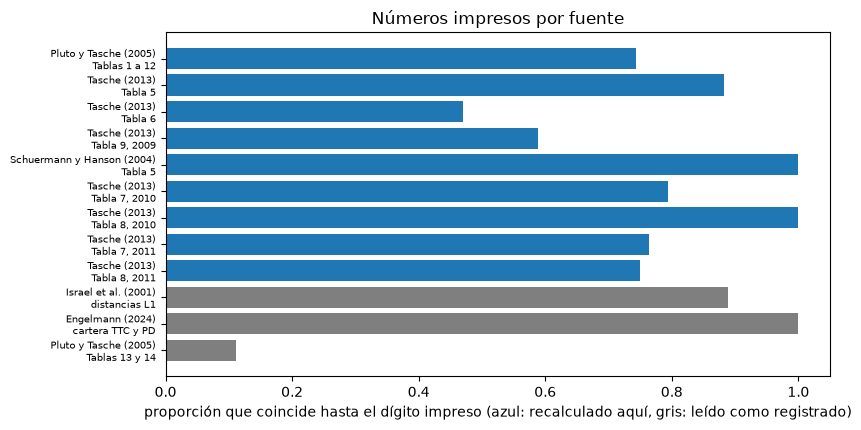

In [15]:
# Draw the share of printed numbers that agree to the printed digit, by source
labels = [r[0].replace(", ", "\n", 1) for r in tally]
shares = [r[2] / r[1] for r in tally]
colours = ["tab:blue" if r[5] == "recomputed" else "tab:grey" for r in tally]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.barh(range(len(tally)), shares, color=colours)
ax.set_yticks(range(len(tally)))
ax.set_yticklabels(labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("proporción que coincide hasta el dígito impreso (azul: recalculado aquí, gris: leído como registrado)")
ax.set_title("Números impresos por fuente")
fig.tight_layout()
plt.show()

La tabla de Schuermann y Hanson y los números de Engelmann alcanzan una proporción completa, y la Tabla 8 de Tasche está en ella o cerca. Las barras más cortas son las tablas impresas con más dígitos o calculadas por simulación: las Tablas 6 y 7 de Tasche, donde el motor falla la impresión por una o dos unidades del último dígito y nunca por más de 0,0013 puntos; la Tabla 9, cuyas razones de verosimilitud salen del solucionador de ajuste cuasi de momentos del propio artículo, con un desfase de cerca de 0,2%; y las Tablas 13 y 14 multiperíodo de Pluto y Tasche, impresiones de Monte Carlo que quedan de 1% a 5% sobre la cuadratura del motor al 99% y al 99,9%, donde coinciden 4 de 36 celdas. Una barra bajo uno es un número que el motor reproduce a una o dos unidades del último dígito, como muestran las mayores brechas impresas arriba, y no un error de método. De igual modo, una barra en uno no es prueba de corrección: dice que el motor y el artículo coinciden, y un artículo puede diferir de su propio texto.

## Resultados

**Respuesta:** En su mayoría sí, y cada falla es pequeña y tiene una causa registrada. De los 438 números impresos que los casos de calificaciones y calibración ponen junto al motor, 313 coinciden hasta el dígito impreso; 381 se recalculan en este notebook desde las tasas y perfiles versionados y 57 se leen como los registran los artefactos. La mayor falla en las Tablas 1 a 12 de Pluto y Tasche es de 0,0951 puntos porcentuales (Tabla 12, grado B al 99,9%, impreso 9,54 frente a 9,4449), en las Tablas 5, 6, 7 y 8 de Tasche a lo más 0,0057 puntos porcentuales, y en la Tabla 9 las razones de verosimilitud difieren hasta 0,3579 porque el solucionador del propio artículo tiene un desfase. Los 18 números de Schuermann y Hanson coinciden todos, y los valores p de Jeffreys y binomial del motor igualan dos cálculos independientes dentro de 5,7e-12 y 5,6e-16.

- **Lo que existe.** Recalculado aquí: las Tablas 1 a 12 de Pluto y Tasche, 125 de 168 celdas (mayor brecha 0,0951 puntos); la Tabla 5 de Tasche, 15 de 17 (0,0013) y la Tabla 6, 8 de 17 (0,0013); su Tabla 7, 54 de 68 en 2010 y 52 de 68 en 2011 (0,0005 y 0,0004), la Tabla 8, 4 de 4 y 3 de 4 (0,0035 y 0,0057) y la Tabla 9, 10 de 17; la Tabla 5 de Schuermann y Hanson, 18 de 18, a los seis decimales impresos. Leído como registrado: Israel, Rosenthal y Wei, 8 de 9 distancias (mayor brecha 0,0004 en la distancia L1); Engelmann, 12 de 12 números; y las Tablas 13 y 14 multiperíodo de Pluto y Tasche, 4 de 36 celdas hasta el dígito.
- **Las brechas están registradas y explicadas.** La única distancia de Israel et al. que discrepa imprime 0,1169 donde la matriz da 0,1165, y es igual a 0,1169 desde el generador impreso del artículo. Los valores p impresos de Tasche (4,6, 8,0, 4,0 y 11,3% en 2010; 78,5, 89,4, 36,6 y 82,2% en 2011) quedan a menos de 0,36 puntos de los del artefacto, de 100.000 simulaciones frente a las 2.000 del artículo. De las 168 celdas de las Tablas 1 a 12 de Pluto y Tasche, 43 difieren de la impresión en una unidad del último dígito o más, y 11 en más de una unidad, listadas arriba: la Tabla 4 al 75% (la impresión es la cota al 76,3%), y las Tablas 11 y 12, que escalan las cotas impresas y redondeadas de las Tablas 4 y 8; B al 99,9% imprime 9,54 frente a 9,44.
- **Recálculos independientes.** En una grilla de 36 casos los valores p de Jeffreys del motor igualan la función de distribución Beta calculada por cuadratura de su densidad (mayor diferencia 5,7e-12) y sus valores p binomiales igualan la suma racional exacta de los términos binomiales (5,6e-16): 72 de 72 dentro de 1e-9. Se descarta la comparación con las llamadas propias de SciPy, porque el motor hace esas llamadas y la diferencia solo podría ser 0.
- **Leído en otra parte o no vuelto a correr aquí.** La exposición de Hull-White frente a ORE se demuestra en el notebook 08 del tema de contraparte y se lee allí. La igualdad del estimador de cohortes con `transitionMatrix` es una prueba del motor (RV-415) que este notebook no vuelve a correr, así que se informa y no se cuenta.
- **La afirmación.** Los seis enunciados de BS-2 que este notebook puede leer se listan con sus valores.

Lo que este notebook no muestra: las reconciliaciones de los otros casos (los notebooks de sus temas nombran sus referencias), ni las entradas de Israel, Rosenthal y Wei y de Engelmann, que la licencia mantiene fuera del repositorio.

## Resumen

- El motor recalcula las tablas impresas de tres artículos desde las tasas y perfiles versionados, y coincide hasta el dígito impreso en la mayoría de los números; las fallas son de una o dos unidades del último dígito, cada una con su explicación.
- Otros dos artículos se cuentan como los registran los artefactos, y sus brechas se listan con sus causas.
- Una comparación con la misma llamada que hace el motor prueba solo la parametrización; los valores p se contrastan en cambio con una cuadratura y con una suma exacta.
- La reconciliación de Hull-White frente a ORE se demuestra en el tema 08; la igualdad con `transitionMatrix` es una prueba del motor que este notebook informa y no vuelve a correr.
- La afirmación BS-2 cuenta lo que existe; no dice que cada número del motor esté reconciliado.

**Qué probar después.** Recalcula la Tabla 4 de Pluto y Tasche con otro nivel de confianza y compárala con la cota exacta; luego lee los notebooks del tema siguiente.

## Referencias

- Israel, R. B., Rosenthal, J. S. y Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, with applications to credit ratings, Mathematical Finance 11(2). https://doi.org/10.1111/1467-9965.00114
- Schuermann, T. y Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, Tabla 5. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), Tablas 5 a 9. https://doi.org/10.21314/jcr.2013.169
- Pluto, K. y Tasche, D. (2005), Estimating probabilities of default for low default portfolios, arXiv cond-mat/0411699, Tablas 1 a 14. https://arxiv.org/abs/cond-mat/0411699
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892, sección 4.
- SciPy `scipy.stats.beta` y `scipy.stats.binom`, en la versión fijada de notebooks/requirements.txt, NumPy `numpy.polynomial.legendre`, y los módulos `math` y `fractions` de la biblioteca estándar de Python.